# Jobsheet 5

## Setup Environment

In [ ]:
%pip install -q transformers

In [ ]:
import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"     # tanpa GPU: jalankan versi diperkecil
CEPAT = DEVICE == "cpu"   # tanpa GPU: jalankan versi diperkecil
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    IMG     = 128 if CEPAT else 256,    #ukuran sisi citar (pixel)
    N_TRAIN = 320 if CEPAT else 2000,   # jumlah citra latih (dari daftar traincal resmi)
    N_TEST  = 100 if CEPAT else 500,    # jumlah citra uji (dari daftar testcal resmi)
    BATCH   = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32       # lebar channel unet
)

print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}   # catatan waktu tiap bagian

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


## Praktikum D1: Mengenal Data Segmentasi Oxford-IIIT Pet

 nilai 1 untuk hewan, 2 untuk latar, dan 3 untuk batas yang ragu-ragu.Kita ubah trimap menjadi masker biner (hewan = 1, latar = 0) dan masker valid yang bernilai 0 pada piksel batas.

Citra latih: 2000 | citra uji: 500 | waktu 24.9 detik
Jumlah ras pada data latih: 37
Bentuk x: (3, 256, 256) | y: (1, 256, 256) | valid: (1, 256, 256)
Proporsi piksel  hewan: 0.301 | latar: 0.584 | batas: 0.114


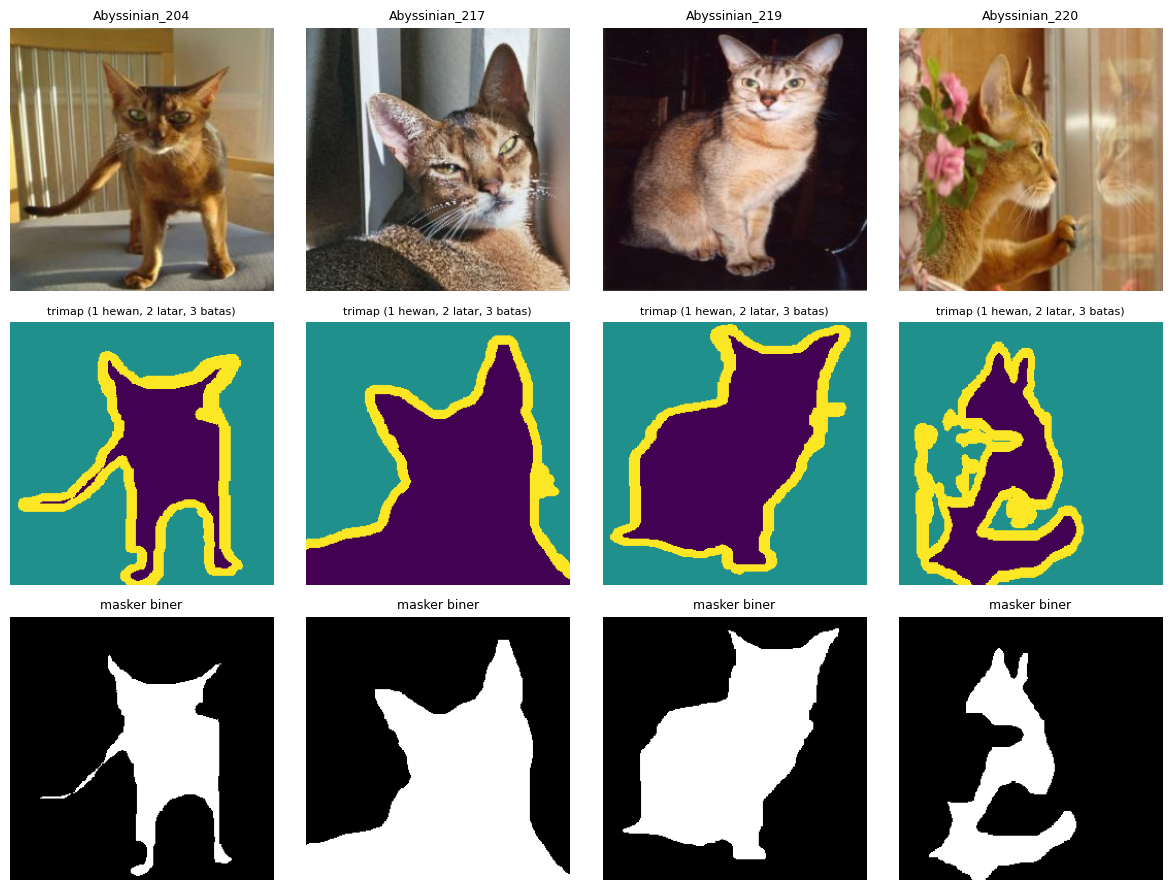

In [ ]:
import os
import tarfile
import time
import urllib.request
import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

# === D1.1 Unduh subset Oxford-IIIT Pet langsung dari server resmi VGG ===
URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)

    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(URL_ANN, ann)

    split, trimaps = {}, {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        split[line.split()[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return (
            sorted(i for i in ada if split.get(i) == "train"),
            sorted(i for i in ada if split.get(i) == "test")
        )

    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia di", root)
        return tr[:n_train], te[:n_test]

    with urllib.request.urlopen(URL_IMG) as resp, tarfile.open(fileobj=resp, mode="r|gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"):
                continue
            iid = nama[:-4]
            s = split.get(iid)
            if iid not in trimaps or s is None:
                continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test):
                continue

            with open(f"{root}/images/{nama}", "wb") as f:
                f.write(t.extractfile(m).read())
            with open(f"{root}/trimaps/{iid}.png", "wb") as f:
                f.write(trimaps[iid])

            (tr if s == "train" else te).append(iid)
            if len(tr) >= n_train and len(te) >= n_test:
                break

    tr, te = hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")
print("Jumlah ras pada data latih:", len({i.rsplit('_', 1)[0] for i in ID_TRAIN}))

# === D1.2 Dataset PyTorch: citra RGB + masker biner + masker valid ===
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    # Semua data dimuat sekali ke memori dalam bentuk uint8 agar pelatihan cepat
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)  # (N,3,H,W) uint8
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))                      # (N,H,W)   uint8
        self.augment = augment

    def __len__(self):
        return len(self.img)

    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)       # 1 = hewan, 0 = latar
        valid = (tri != 3).float().unsqueeze(0)   # 0 pada piksel batas (diabaikan)

        if self.augment and random.random() < 0.5:    # augment: flip horizontal
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)

        return (x - MEAN) / STD, y, valid

t0 = time.time()
ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test  = PetSegDataset(ID_TEST,  CFG["IMG"], augment=False)  # Diperbaiki: augment=False untuk data uji

dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test  = torch.utils.data.DataLoader(ds_test,  batch_size=CFG["BATCH"], shuffle=False)

x, y, v = ds_train[0]
print("Bentuk x:", tuple(x.shape), "| y:", tuple(y.shape), "| valid:", tuple(v.shape))
tri_all = ds_train.tri
print("Proporsi piksel  hewan: %.3f | latar: %.3f | batas: %.3f" % tuple(((tri_all == k).float().mean().item()) for k in (1, 2, 3)))
WAKTU["D1 data"] = time.time() - t0

# === D1.3 Visualisasi: citra, trimap, dan masker biner ===
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for k in range(4):
    x, y, v = ds_test[k]
    ax[0, k].imshow(denorm(x))
    ax[0, k].set_title(ID_TEST[k], fontsize=9)

    ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3)
    ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)

    ax[2, k].imshow(y[0], cmap="gray")
    ax[2, k].set_title("masker biner", fontsize=9)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d1_contoh_data.png", dpi=120)
plt.show()

## Tugas Kecil D1
Hitung proporsi piksel hewan, latar, dan batas pada data uji. Mengapa piksel batas lebih baik diabaikan daripada dipaksa masuk ke salah satu kelas?

In [ ]:
# === Hitung proporsi piksel pada data uji (ds_test) ===
tri_test_all = ds_test.tri
prop_test = [
    (tri_test_all == k).float().mean().item() for k in (1, 2, 3)
]

print(
    f"Proporsi piksel uji - Hewan: {prop_test[0]:.3f} | Latar:"
    f" {prop_test[1]:.3f} | Batas: {prop_test[2]:.3f}"
)

Proporsi piksel uji - Hewan: 0.301 | Latar: 0.575 | Batas: 0.124


## Praktikum D2: Membangun dan Melatih U-Net dari Nol

In [ ]:
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# === D2.1 Arsitektur U-Net Dasar ===
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True)
        )

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()  # bottleneck
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))   # skip connection
        return self.head(x)  # logit (B, 1, H, W)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)
print("Jumlah parameter U-Net: %.2f juta" % (sum(p.numel() for p in unet.parameters()) / 1e6))
print("Uji bentuk keluaran:", tuple(unet(torch.zeros(2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE)).shape))

Jumlah parameter U-Net: 7.76 juta
Uji bentuk keluaran: (2, 1, 256, 256)


In [ ]:
# === D2.2 Loss BCE + Dice dengan masker valid, dan fungsi pelatihan umum ===
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)

    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)

    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(x)

        model.eval()
        tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v).item() * len(x)

        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs}  loss latih {riwayat['train'][-1]:.4f}  loss uji {riwayat['test'][-1]:.4f}  ({time.time()-t0:.0f} s)")

    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

[U-Net (dari nol)] epoch 1/15  loss latih 0.9094  loss uji 0.8130  (49 s)
[U-Net (dari nol)] epoch 2/15  loss latih 0.7303  loss uji 0.8284  (106 s)
[U-Net (dari nol)] epoch 3/15  loss latih 0.6444  loss uji 0.6296  (159 s)
[U-Net (dari nol)] epoch 4/15  loss latih 0.5922  loss uji 0.7047  (214 s)
[U-Net (dari nol)] epoch 5/15  loss latih 0.5408  loss uji 0.5326  (268 s)
[U-Net (dari nol)] epoch 6/15  loss latih 0.4775  loss uji 0.4549  (323 s)
[U-Net (dari nol)] epoch 7/15  loss latih 0.4461  loss uji 0.4757  (377 s)
[U-Net (dari nol)] epoch 8/15  loss latih 0.4226  loss uji 0.3781  (432 s)
[U-Net (dari nol)] epoch 9/15  loss latih 0.3898  loss uji 0.3646  (487 s)
[U-Net (dari nol)] epoch 10/15  loss latih 0.3636  loss uji 0.3716  (541 s)
[U-Net (dari nol)] epoch 11/15  loss latih 0.3430  loss uji 0.4194  (596 s)
[U-Net (dari nol)] epoch 12/15  loss latih 0.3303  loss uji 0.4499  (651 s)
[U-Net (dari nol)] epoch 13/15  loss latih 0.3188  loss uji 0.3336  (705 s)
[U-Net (dari nol)] epo

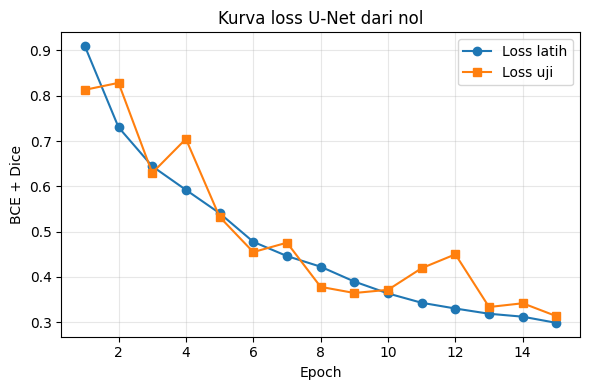

In [ ]:
# === D2.3 Kurva loss U-Net ===
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch")
plt.ylabel("BCE + Dice")
plt.title("Kurva loss U-Net dari nol")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120)
plt.show()

## Tugas Kecil D2
Ubah w_dice=0 (hanya BCE) lalu latih ulang. Bandingkan IoU pada D3. Kapan
Dice loss lebih membantu?

In [ ]:
import time
import torch
import torch.nn.functional as F

# Fungsi loss khusus BCE saja (w_dice = 0)
def bce_only_loss(logit, y, valid, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    return (bce * valid).sum() / valid.sum().clamp_min(1)

# Fungsi pelatihan khusus untuk BCE-only
def latih_bce_only(model, forward, epochs, lr, nama):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_only_loss(forward(model, x), y, v)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(x)

        model.eval()
        tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_only_loss(forward(model, x), y, v).item() * len(x)

        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs}  loss latih {riwayat['train'][-1]:.4f}  loss uji {riwayat['test'][-1]:.4f}  ({time.time()-t0:.0f} s)")

    WAKTU[nama] = time.time() - t0
    return riwayat

# Inisialisasi U-Net baru dan latih dengan BCE murni
unet_bce = UNet(base=CFG["BASE_CH"]).to(DEVICE)
set_seed(42)
hist_unet_bce = latih_bce_only(unet_bce, lambda m, x: m(x), CFG["EP_UNET"], 1e-3, "U-Net (BCE only)")

[U-Net (BCE only)] epoch 1/15  loss latih 0.5149  loss uji 0.4134  (56 s)
[U-Net (BCE only)] epoch 2/15  loss latih 0.4148  loss uji 0.4090  (110 s)
[U-Net (BCE only)] epoch 3/15  loss latih 0.3824  loss uji 0.4398  (165 s)
[U-Net (BCE only)] epoch 4/15  loss latih 0.3619  loss uji 0.3504  (220 s)
[U-Net (BCE only)] epoch 5/15  loss latih 0.3508  loss uji 0.3606  (274 s)
[U-Net (BCE only)] epoch 6/15  loss latih 0.3199  loss uji 0.3586  (329 s)
[U-Net (BCE only)] epoch 7/15  loss latih 0.3013  loss uji 0.3204  (383 s)
[U-Net (BCE only)] epoch 8/15  loss latih 0.2711  loss uji 0.3432  (438 s)
[U-Net (BCE only)] epoch 9/15  loss latih 0.2636  loss uji 0.2845  (493 s)
[U-Net (BCE only)] epoch 10/15  loss latih 0.2463  loss uji 0.2248  (548 s)
[U-Net (BCE only)] epoch 11/15  loss latih 0.2288  loss uji 0.2469  (602 s)
[U-Net (BCE only)] epoch 12/15  loss latih 0.2186  loss uji 0.2021  (657 s)
[U-Net (BCE only)] epoch 13/15  loss latih 0.2077  loss uji 0.2202  (712 s)
[U-Net (BCE only)] epo

## Praktikum D3: Metrik Evaluasi Segmentasi
Loss yang turun belum tentu berarti segmentasi bagus. Kita hitung TP, FP, FN, dan TN pada seluruh piksel valid data uji, lalu menurunkan IoU, Dice, pixel accuracy dan mIoU. IoU per citra juga disimpan untuk analisis kesalahan pada D6.

In [ ]:
import torch
import matplotlib.pyplot as plt

# === D3.1 Fungsi metrik dan evaluasi ===
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0
    iou_per_citra = []

    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()

        tp = (pred * y * v).sum(dim=(1, 2, 3))
        fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3))
        tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))

        TP += tp.sum().item()
        FP += fp.sum().item()
        FN += fn.sum().item()
        TN += tn.sum().item()

        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()

    iou_fg = TP / (TP + FP + FN)
    iou_bg = TN / (TN + FN + FP)

    return {
        "IoU_hewan": iou_fg,
        "IoU_latar": iou_bg,
        "mIoU": (iou_fg + iou_bg) / 2,
        "Dice": 2 * TP / (2 * TP + FP + FN),
        "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
        "iou_per_citra": iou_per_citra
    }

def ringkas(m):
    return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

{'IoU_hewan': 0.8254, 'IoU_latar': 0.9034, 'mIoU': 0.8644, 'Dice': 0.9043, 'PixelAcc': 0.9337}


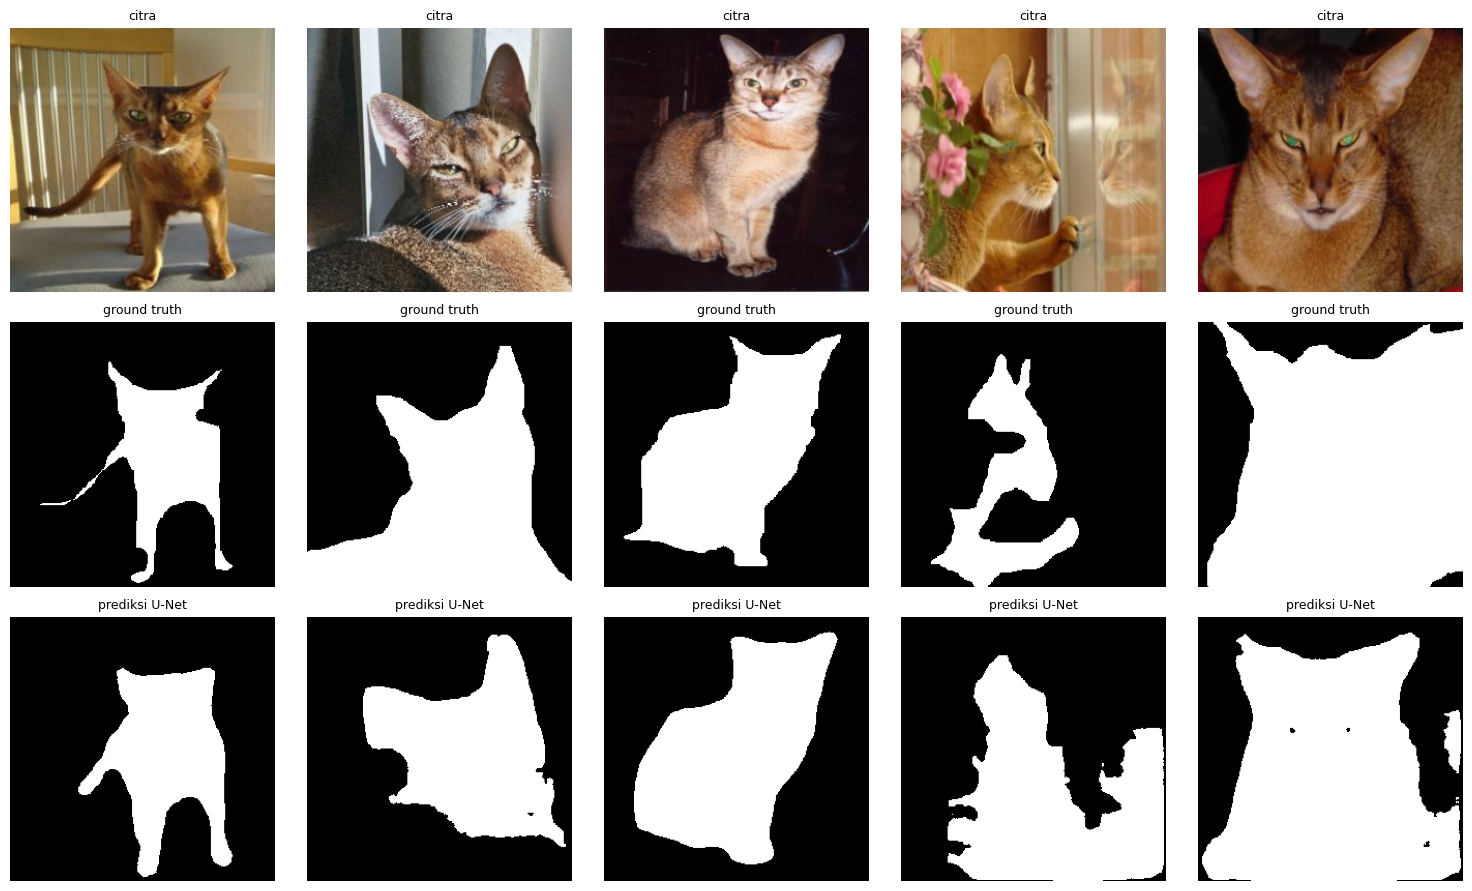

In [ ]:
# === D3.2 Visualisasi prediksi U-Net ===
@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)

fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x))
    ax[0, j].set_title("citra", fontsize=9)

    ax[1, j].imshow(y[0], cmap="gray")
    ax[1, j].set_title("ground truth", fontsize=9)

    ax[2, j].imshow(p_unet[j, 0], cmap="gray")
    ax[2, j].set_title("prediksi U-Net", fontsize=9)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png", dpi=120)
plt.show()

## Tugas Kecil D3
Ubah ambang thr dari 0,5 menjadi 0,3 dan 0,7. Bagaimana pengaruhnya terhadap IoU dan Dice?

In [ ]:
# Evaluasi dengan berbagai nilai threshold (ambang batas)
print("--- Evaluasi Default (thr = 0.5) ---")
print(ringkas(HASIL["U-Net (dari nol)"]))

print("\n--- Evaluasi dengan thr = 0.3 (Lebih Longgar) ---")
hasil_03 = evaluasi(unet, fwd_unet, thr=0.3)
print(ringkas(hasil_03))

print("\n--- Evaluasi dengan thr = 0.7 (Lebih Ketat) ---")
hasil_07 = evaluasi(unet, fwd_unet, thr=0.7)
print(ringkas(hasil_07))

--- Evaluasi Default (thr = 0.5) ---
{'IoU_hewan': 0.8254, 'IoU_latar': 0.9034, 'mIoU': 0.8644, 'Dice': 0.9043, 'PixelAcc': 0.9337}

--- Evaluasi dengan thr = 0.3 (Lebih Longgar) ---
{'IoU_hewan': 0.8167, 'IoU_latar': 0.8931, 'mIoU': 0.8549, 'Dice': 0.8991, 'PixelAcc': 0.9276}

--- Evaluasi dengan thr = 0.7 (Lebih Ketat) ---
{'IoU_hewan': 0.8168, 'IoU_latar': 0.9039, 'mIoU': 0.8604, 'Dice': 0.8992, 'PixelAcc': 0.9327}


## Praktikum D4: Transfer Learning dengan DeepLabV3
Kita memanfaatkan DeepLabV3-MobileNetV3-Large yang sudah dilatih torchvision.
Lapisan klasifikasi terakhir (21 kelas PASCAL VOC) diganti menjadi 1 kanal Backbone diberi learning rate 1e-4, kepala baru 1e-3.

In [ ]:
import torch
import torch.nn as nn
from torchvision.models.segmentation import (
    deeplabv3_mobilenet_v3_large,
    DeepLabV3_MobileNet_V3_Large_Weights
)

set_seed(42)

# Inisialisasi DeepLabV3 dengan bobot pre-trained
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)   # Mengubah 21 kelas VOC -> 1 kanal
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)

print("Jumlah parameter DeepLabV3-MobileNetV3: %.2f juta" % (sum(p.numel() for p in dlv3.parameters()) / 1e6))

fwd_dlv3 = lambda m, x: m(x)["out"]

# Pengaturan learning rate berbeda untuk backbone dan kepala baru
groups = [
    {"params": dlv3.backbone.parameters(), "lr": 1e-4},     # backbone: lr kecil (fine-tuning)
    {"params": dlv3.classifier.parameters(), "lr": 1e-3}    # kepala baru: lr besar
]

# Pelatihan model DeepLabV3
hist_dlv3 = latih(
    dlv3,
    fwd_dlv3,
    CFG["EP_DLV3"],
    1e-3,
    "DeepLabV3-MobileNetV3 (pra-latih)",
    param_groups=groups
)

# Evaluasi model
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 133MB/s]


Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/6  loss latih 0.1819  loss uji 0.1292  (24 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/6  loss latih 0.0925  loss uji 0.1252  (47 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 3/6  loss latih 0.0717  loss uji 0.1027  (70 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 4/6  loss latih 0.0588  loss uji 0.1056  (94 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 5/6  loss latih 0.0525  loss uji 0.1113  (117 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 6/6  loss latih 0.0449  loss uji 0.1029  (141 s)
{'IoU_hewan': 0.9535, 'IoU_latar': 0.9752, 'mIoU': 0.9644, 'Dice': 0.9762, 'PixelAcc': 0.9836}


## Tugas Kecil D4
Bekukan backbone (requires_grad=False) dan latih hanya kepala klasifikasi.
Bandingkan waktu per epoch dan mIoU.

In [ ]:
import torch
import torch.nn as nn
from torchvision.models.segmentation import (
    deeplabv3_mobilenet_v3_large,
    DeepLabV3_MobileNet_V3_Large_Weights
)

set_seed(42)

# Inisialisasi model DeepLabV3
dlv3_frozen = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3_frozen.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
dlv3_frozen.aux_classifier = None
dlv3_frozen = dlv3_frozen.to(DEVICE)

# --- BEKUKAN BACKBONE ---
for param in dlv3_frozen.backbone.parameters():
    param.requires_grad = False

fwd_dlv3 = lambda m, x: m(x)["out"]

# Karena backbone dibekukan, optimizer di dalam fungsi latih()
# secara otomatis hanya akan memperbarui parameter yang aktif (kepala klasifikasi)
hist_dlv3_frozen = latih(
    dlv3_frozen,
    fwd_dlv3,
    CFG["EP_DLV3"],
    1e-3,
    "DeepLabV3-MobileNetV3 (Frozen Backbone)"
)

# Evaluasi model
HASIL["DeepLabV3-MobileNetV3 (Frozen)"] = evaluasi(dlv3_frozen, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (Frozen)"]))

[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 1/6  loss latih 0.2182  loss uji 0.1420  (13 s)
[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 2/6  loss latih 0.1440  loss uji 0.1517  (27 s)
[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 3/6  loss latih 0.1285  loss uji 0.1395  (40 s)
[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 4/6  loss latih 0.1106  loss uji 0.1390  (53 s)
[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 5/6  loss latih 0.1016  loss uji 0.1397  (67 s)
[DeepLabV3-MobileNetV3 (Frozen Backbone)] epoch 6/6  loss latih 0.0943  loss uji 0.1520  (80 s)
{'IoU_hewan': 0.9258, 'IoU_latar': 0.96, 'mIoU': 0.9429, 'Dice': 0.9615, 'PixelAcc': 0.9733}


## Praktikum D5: Fine-Tuning SegFormer-B0
SegFormer dimuat dari Hugging Face dengan num_labels=1. Keluaran SegFormer
berukuran seperempat resolusi masukan sehingga perlu di-upsample (interpolasi bilinear) sebelum dihitung loss-nya.

In [ ]:
import transformers
from transformers import SegformerForSemanticSegmentation

transformers.logging.set_verbosity_error()
set_seed(42)

# === D5.1 Muat SegFormer-B0 dan latih ===
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B0: %.2f juta" % (sum(p.numel() for p in segf.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits  # resolusi 1/4 dari input
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pra-latih)")

HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/6  loss latih 0.3106  loss uji 0.1541  (28 s)
[SegFormer-B0 (pra-latih)] epoch 2/6  loss latih 0.1508  loss uji 0.1519  (56 s)
[SegFormer-B0 (pra-latih)] epoch 3/6  loss latih 0.0960  loss uji 0.1151  (83 s)
[SegFormer-B0 (pra-latih)] epoch 4/6  loss latih 0.0786  loss uji 0.1194  (111 s)
[SegFormer-B0 (pra-latih)] epoch 5/6  loss latih 0.0914  loss uji 0.1156  (138 s)
[SegFormer-B0 (pra-latih)] epoch 6/6  loss latih 0.1240  loss uji 0.1270  (165 s)
{'IoU_hewan': 0.9325, 'IoU_latar': 0.9634, 'mIoU': 0.9479, 'Dice': 0.965, 'PixelAcc': 0.9757}


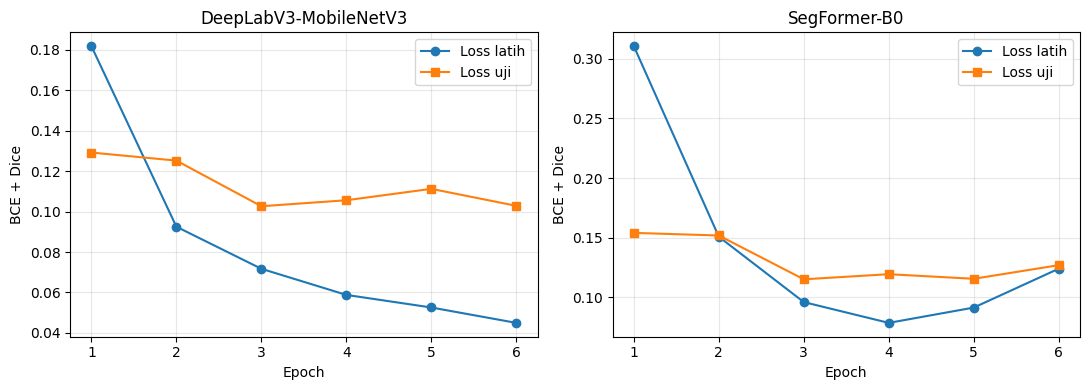

In [ ]:
# === D5.2 Kurva loss model pra-latih ===
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih")
    a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama)
    a.set_xlabel("Epoch")
    a.set_ylabel("BCE + Dice")
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png", dpi=120)
plt.show()

## Tugas Kecil D5
Ganti nvidia/mit-b0 dengan nvidia/mit-b1. Catat jumlah parameter, waktu
per epoch, dan mIoU.

In [ ]:
import transformers
from transformers import SegformerForSemanticSegmentation

transformers.logging.set_verbosity_error()
set_seed(42)

# === Muat SegFormer-B1 dan latih ===
segf_b1 = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b1", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B1: %.2f juta" % (sum(p.numel() for p in segf_b1.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits  # resolusi 1/4 dari input
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf_b1 = latih(segf_b1, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B1 (pra-latih)")

HASIL["SegFormer-B1 (pra-latih)"] = evaluasi(segf_b1, fwd_segf)
print(ringkas(HASIL["SegFormer-B1 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B1: 13.68 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 54.7MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B1 (pra-latih)] epoch 1/6  loss latih 0.2891  loss uji 0.1239  (47 s)
[SegFormer-B1 (pra-latih)] epoch 2/6  loss latih 0.1255  loss uji 0.1103  (93 s)
[SegFormer-B1 (pra-latih)] epoch 3/6  loss latih 0.0835  loss uji 0.1266  (140 s)
[SegFormer-B1 (pra-latih)] epoch 4/6  loss latih 0.0677  loss uji 0.0979  (186 s)
[SegFormer-B1 (pra-latih)] epoch 5/6  loss latih 0.0581  loss uji 0.1105  (233 s)
[SegFormer-B1 (pra-latih)] epoch 6/6  loss latih 0.0531  loss uji 0.0968  (279 s)
{'IoU_hewan': 0.9507, 'IoU_latar': 0.9737, 'mIoU': 0.9622, 'Dice': 0.9747, 'PixelAcc': 0.9826}


## Praktikum D6: Perbandingan Model dan Analisis Kesalahan
Langkah terakhir adalah membandingkan ketiga model secara kuantitatif dan kualitatif, kemudian mencari citra dengan IoU terendah. Peta kesalahan memakai warna hijau untuk TP, merah untuk FP, dan biru untuk FN.

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === D6.1 Tabel perbandingan (Versi Aman / Anti-Error) ===
param = {
    "U-Net (dari nol)": unet,
    "DeepLabV3-MobileNetV3 (pra-latih)": dlv3,
    "DeepLabV3-MobileNetV3 (Frozen)": dlv3_frozen,  # Sesuaikan jika variabelnya ada
    "SegFormer-B0 (pra-latih)": segf
}

tabel_data = []
for k, v in HASIL.items():
    # Hitung parameter jika modelnya terdaftar di kamus param, jika tidak beri 0
    if k in param:
        n_params = round(sum(p.numel() for p in param[k].parameters()) / 1e6, 2)
    else:
        n_params = 0.0

    # Ambil waktu latih dengan aman (default 0 jika tidak ada di kamus WAKTU)
    waktu_latih = round(WAKTU.get(k, 0.0), 1)

    row = {
        "Model": k,
        **ringkas(v),
        "Parameter (juta)": n_params,
        "Waktu latih (s)": waktu_latih
    }
    tabel_data.append(row)

tabel = pd.DataFrame(tabel_data)

print(tabel.to_string(index=False))
tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)

with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({
        "perangkat": DEVICE,
        "mode": "CEPAT" if CEPAT else "PENUH",
        "cfg": CFG,
        "hasil": {k: ringkas(v) for k, v in HASIL.items()},
        "waktu_detik": WAKTU
    }, f, indent=2)

                            Model  IoU_hewan  IoU_latar   mIoU   Dice  PixelAcc  Parameter (juta)  Waktu latih (s)
                 U-Net (dari nol)     0.8254     0.9034 0.8644 0.9043    0.9337              7.76            815.9
DeepLabV3-MobileNetV3 (pra-latih)     0.9535     0.9752 0.9644 0.9762    0.9836             11.02            140.7
   DeepLabV3-MobileNetV3 (Frozen)     0.9258     0.9600 0.9429 0.9615    0.9733             11.02              0.0
         SegFormer-B0 (pra-latih)     0.9325     0.9634 0.9479 0.9650    0.9757              3.71            165.5
         SegFormer-B1 (pra-latih)     0.9507     0.9737 0.9622 0.9747    0.9826              0.00            279.4


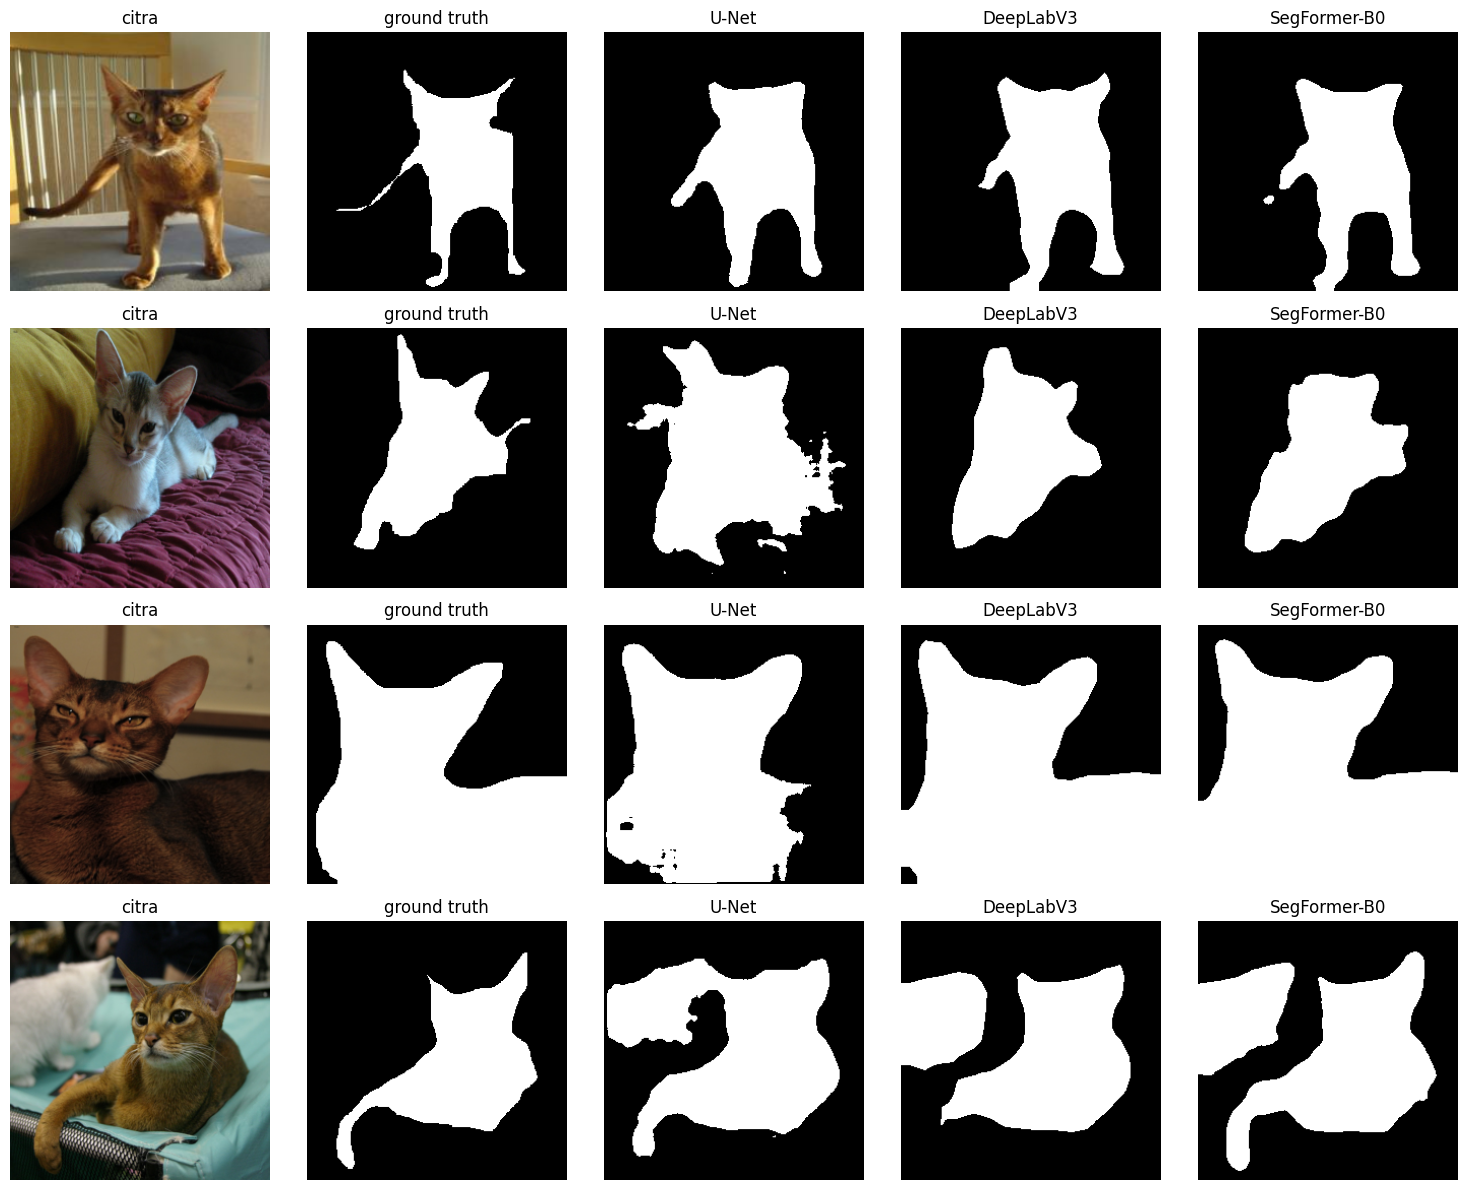

In [ ]:
# === D6.2 Contoh prediksi ketiga model ===
model_fwd = [
    ("U-Net", unet, fwd_unet),
    ("DeepLabV3", dlv3, fwd_dlv3),
    ("SegFormer-B0", segf, fwd_segf)
]

idx_vis = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}

for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x))
    ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 0].set_title("citra")
    ax[r, 1].set_title("ground truth")

    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray")
        ax[r, c + 2].set_title(n)

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png", dpi=110)
plt.show()

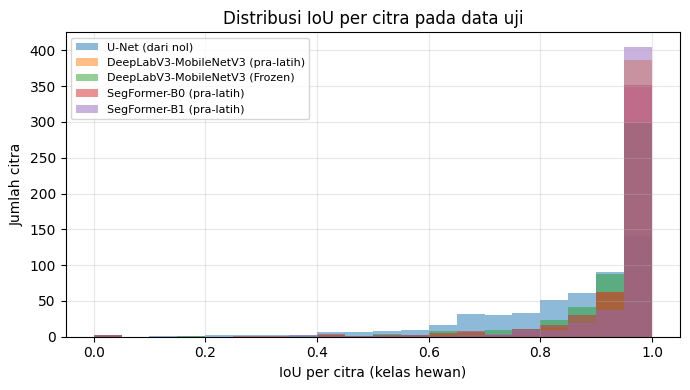

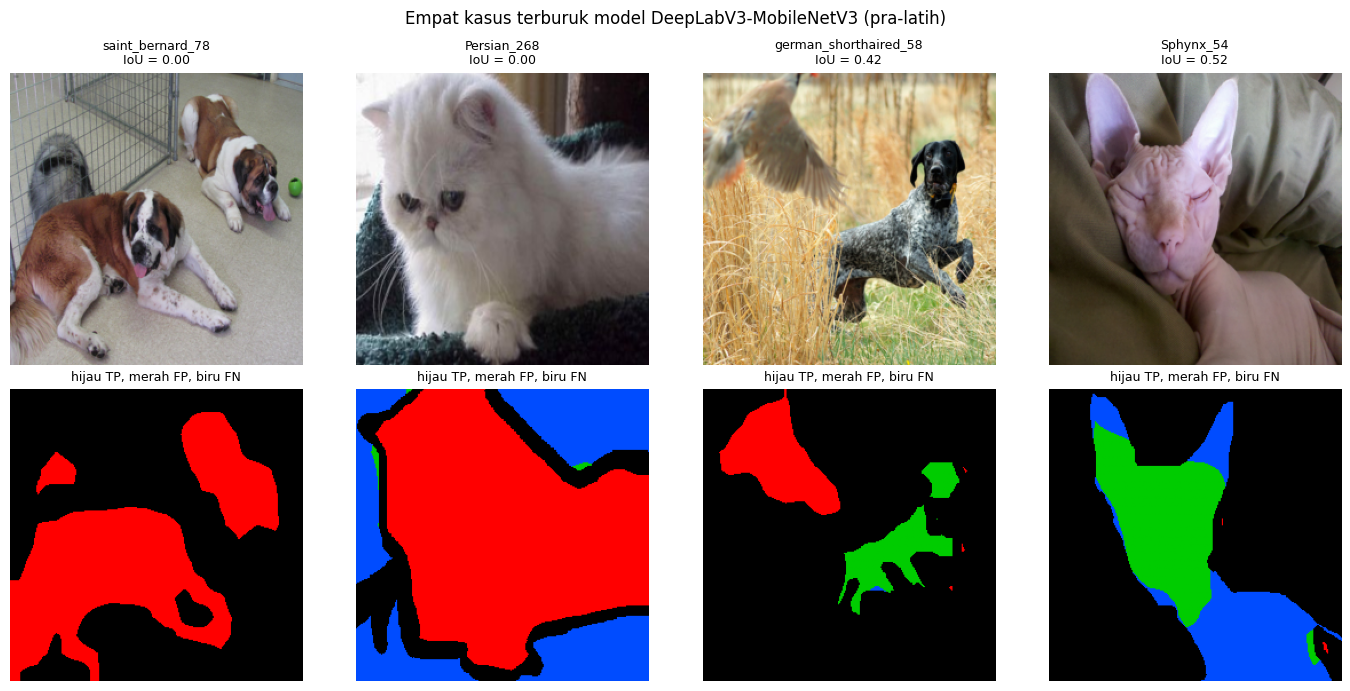

Model terbaik: DeepLabV3-MobileNetV3 (pra-latih) | IoU terendah: [0.0, 0.003, 0.421, 0.523]


In [ ]:
# === D6.3 Analisis kesalahan: distribusi IoU per citra dan kasus terburuk ===
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=0.5, label=n)

plt.xlabel("IoU per citra (kelas hewan)")
plt.ylabel("Jumlah citra")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120)
plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])
mdl, fw = {
    n: (m, f) for n, m, f in [
        ("U-Net (dari nol)", unet, fwd_unet),
        ("DeepLabV3-MobileNetV3 (pra-latih)", dlv3, fwd_dlv3),
        ("SegFormer-B0 (pra-latih)", segf, fwd_segf)
    ]
}[terbaik]

iou = np.array(HASIL[terbaik]["iou_per_citra"])
buruk = np.argsort(iou)[:4].tolist()
pb = prediksi(mdl, fw, buruk)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
    x, y, v = ds_test[i]
    p = pb[j, 0]
    g = y[0]
    val = v[0]

    peta = np.zeros((*g.shape, 3))
    peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, 0.8, 0]
    peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]
    peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, 0.3, 1]

    ax[0, j].imshow(denorm(x))
    ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta)
    ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)

for a in ax.ravel():
    a.axis("off")

plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110)
plt.show()

print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

## Tugas Kecil D6
Kelompokkan penyebab kesalahan pada kasus terburuk (latar mirip warna bulu,
hewan kecil, oklusi, pencahayaan). Usulkan satu perbaikan dan buktikan dengan eksperimen.

In [ ]:
import torchvision.transforms.functional as TF

class PetSegDatasetAugmented(torch.utils.data.Dataset):
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)  # (N,3,H,W) uint8
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))                      # (N,H,W) uint8
        self.augment = augment

    def __len__(self):
        return len(self.img)

    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)        # 1 = hewan, 0 = latar
        valid = (tri != 3).float().unsqueeze(0)    # 0 pada piksel batas

        if self.augment:
            # 1. Flip horizontal (augmentasi dasar)
            if random.random() < 0.5:
                x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)

            # 2. Tambahan Color Jitter (Mengatasi pencahayaan & warna mirip)
            if random.random() < 0.5:
                # Mengubah brightness dan contrast secara acak
                factor_bri = random.uniform(0.8, 1.2)
                x = torch.clamp(x * factor_bri, 0.0, 1.0)

        return (x - MEAN) / STD, y, valid

# --- Uji Coba Latih Ulang dengan Augmentasi Diperkuat ---
set_seed(42)
ds_train_aug = PetSegDatasetAugmented(ID_TRAIN, CFG["IMG"], augment=True)
dl_train_aug = torch.utils.data.DataLoader(ds_train_aug, batch_size=CFG["BATCH"], shuffle=True)

# Latih ulang model pilihan (misal U-Net atau SegFormer) dengan data yang sudah di-augmentasi
unet_aug = UNet(base=CFG["BASE_CH"]).to(DEVICE)
hist_unet_aug = latih(unet_aug, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (Augmentasi Kuat)")

# Evaluasi hasil baru
HASIL["U-Net (Augmentasi Kuat)"] = evaluasi(unet_aug, fwd_unet)
print("Hasil Evaluasi dengan Augmentasi Kuat:")
print(ringkas(HASIL["U-Net (Augmentasi Kuat)"]))

[U-Net (Augmentasi Kuat)] epoch 1/15  loss latih 0.8798  loss uji 0.8128  (56 s)
[U-Net (Augmentasi Kuat)] epoch 2/15  loss latih 0.6870  loss uji 0.6912  (111 s)
[U-Net (Augmentasi Kuat)] epoch 3/15  loss latih 0.5962  loss uji 0.5735  (165 s)
[U-Net (Augmentasi Kuat)] epoch 4/15  loss latih 0.5302  loss uji 0.5044  (220 s)
[U-Net (Augmentasi Kuat)] epoch 5/15  loss latih 0.4694  loss uji 0.4689  (275 s)
[U-Net (Augmentasi Kuat)] epoch 6/15  loss latih 0.4402  loss uji 0.4293  (329 s)
[U-Net (Augmentasi Kuat)] epoch 7/15  loss latih 0.4185  loss uji 0.5063  (384 s)
[U-Net (Augmentasi Kuat)] epoch 8/15  loss latih 0.3872  loss uji 0.3809  (439 s)
[U-Net (Augmentasi Kuat)] epoch 9/15  loss latih 0.3617  loss uji 0.3330  (494 s)
[U-Net (Augmentasi Kuat)] epoch 10/15  loss latih 0.3520  loss uji 0.3552  (548 s)
[U-Net (Augmentasi Kuat)] epoch 11/15  loss latih 0.3217  loss uji 0.4304  (603 s)
[U-Net (Augmentasi Kuat)] epoch 12/15  loss latih 0.3079  loss uji 0.3192  (658 s)
[U-Net (Augmen

## Penugasan
1. Lakukan satu eksperimen perbaikan pada model terbaik (pilih salah satu: augmentasi tambahan, resolusi lebih besar, epoch lebih banyak, atau loss berbeda) dan laporkan perubahan mIoU.
2. Gunakan sel Penugasan di akhir notebook untuk menyegmentasi minimal tiga foto hewan peliharaan milik sendiri. Tampilkan hasil overlay dan analisis singkat keberhasilan atau kegagalannya.

In [ ]:
# === EKSPERIMEN PERBAIKAN: Menambah Jumlah Epoch Pelatihan ===
# Misal model terbaik kita adalah SegFormer-B0, kita latih tambahan epoch atau latih dari awal dengan ep lebih tinggi
CFG["EP_SEGF_EXT"] = 15  # ditambah dari epoch default sebelumnya

print(f"Melatih ulang model terbaik dengan {CFG['EP_SEGF_EXT']} epoch...")
set_seed(42)

# Inisialisasi ulang model segar
segf_improved = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)

# Latih dengan epoch lebih banyak
hist_segf_improved = latih(segf_improved, fwd_segf, CFG["EP_SEGF_EXT"], 3e-4, "SegFormer-B0 (Epoch Diperbanyak)")

# Evaluasi kembali
HASIL["SegFormer-B0 (Epoch Diperbanyak)"] = evaluasi(segf_improved, fwd_segf)
print("Hasil Evaluasi Model dengan Epoch Diperbanyak:")
print(ringkas(HASIL["SegFormer-B0 (Epoch Diperbanyak)"]))

Melatih ulang model terbaik dengan 15 epoch...


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[SegFormer-B0 (Epoch Diperbanyak)] epoch 1/15  loss latih 0.3130  loss uji 0.1686  (24 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 2/15  loss latih 0.1453  loss uji 0.1416  (48 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 3/15  loss latih 0.0939  loss uji 0.1195  (73 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 4/15  loss latih 0.0802  loss uji 0.1040  (97 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 5/15  loss latih 0.0654  loss uji 0.1213  (121 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 6/15  loss latih 0.0779  loss uji 0.1205  (145 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 7/15  loss latih 0.0841  loss uji 0.1211  (169 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 8/15  loss latih 0.0779  loss uji 0.1237  (193 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 9/15  loss latih 0.0564  loss uji 0.0921  (218 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 10/15  loss latih 0.0380  loss uji 0.1113  (242 s)
[SegFormer-B0 (Epoch Diperbanyak)] epoch 11/15  loss latih 0.0537  loss uji 0.1076  (266 s)
[

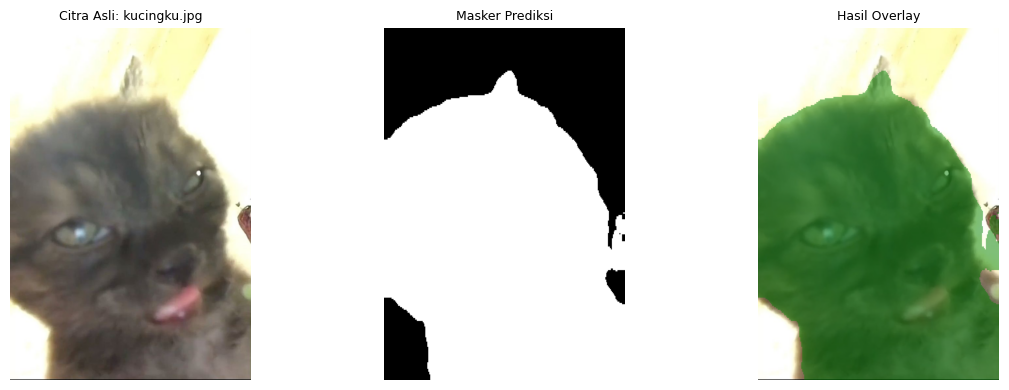

In [ ]:
# === SEL PENUGASAN AKHIR: Segmentasi Foto Hewan Peliharaan Pribadi ===
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

# 1. Tentukan path foto lokalmu di Colab (sesuaikan nama filenya)
# Contoh: letakkan foto di folder kerja atau upload lewat panel sebelah kiri Colab
daftar_foto = ["kucingku.jpg", "anjingku.jpg", "kucing_peliharaan.jpg"] # Ganti dengan nama file fotomu yang ada

@torch.no_grad()
def segmentasi_foto_pribadi(model, forward, image_paths, size=256):
    model.eval()
    fig, axes = plt.subplots(len(image_paths), 3, figsize=(12, 4 * len(image_paths)))

    # Tangani jika hanya 1 foto (agar axes tetap berupa array 2D)
    if len(image_paths) == 1:
        axes = np.expand_dims(axes, 0)

    for idx, path in enumerate(image_paths):
        try:
            # Buka citra asli
            img_pil = Image.open(path).convert("RGB")
            orig_w, orig_h = img_pil.size

            # Resize untuk model
            img_resized = img_pil.resize((size, size), Image.BILINEAR)
            x_np = np.array(img_resized)

            # Tensor PyTorch & Normalisasi sesuai pipeline pelatihan
            x_tensor = torch.from_numpy(x_np).permute(2, 0, 1).float() / 255.0
            x_norm = (x_tensor - MEAN) / STD
            x_batch = x_norm.unsqueeze(0).to(DEVICE)

            # Prediksi model (Sigmoid + Threshold 0.5)
            logit = forward(model, x_batch)
            pred_mask = (torch.sigmoid(logit) > 0.5).float().cpu().numpy()[0, 0] # ukuran (size, size)

            # Resize kembali masker ke ukuran asli citra
            mask_pil = Image.fromarray((pred_mask * 255).astype(np.uint8)).resize((orig_w, orig_h), Image.NEAREST)
            mask_orig = (np.array(mask_pil) > 127).astype(float)

            # Buat visualisasi overlay (misal: warna hijau transparan di atas area hewan)
            img_orig_np = np.array(img_pil)
            overlay = img_orig_np.copy()
            # Warnai piksel prediksi hewan dengan corak hijau
            overlay[mask_orig == 1] = overlay[mask_orig == 1] * 0.5 + np.array([0, 128, 0]) * 0.5

            # Plotting
            axes[idx, 0].imshow(img_orig_np)
            axes[idx, 0].set_title(f"Citra Asli: {path}", fontsize=9)

            axes[idx, 1].imshow(mask_orig, cmap="gray")
            axes[idx, 1].set_title("Masker Prediksi", fontsize=9)

            axes[idx, 2].imshow(overlay)
            axes[idx, 2].set_title("Hasil Overlay", fontsize=9)

        except FileNotFoundError:
            print(f"File '{path}' tidak ditemukan. Pastikan sudah di-upload ke direktori Colab!")

    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Jalankan fungsi menggunakan model terbaik (misal: segf atau unet_aug)
# Pastikan variabel model terbaikmu (misal 'segf') sudah didefinisikan di sel atas
segmentasi_foto_pribadi(segf, fwd_segf, ["kucingku.jpg"])